In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

In [2]:
from matplotlib import rc
rc('text', usetex=True)
rc('font', family='serif')
rc('font', serif='times')
#rc('font', weight='bolder')
rc('mathtext', default='sf')
rc("lines", markeredgewidth=1)
rc("lines", linewidth=1)
rc('axes', labelsize=20) #24
rc("axes", linewidth=0.5) #2)
rc('xtick', labelsize=10)
rc('ytick', labelsize=10)
rc('legend', fontsize=10) #16
rc('ytick', right='True',direction= 'in')
rc('xtick', top='True',direction= 'in')
rc('xtick.major', pad=15) #8)
rc('ytick.major', pad=15) #8)
rc('xtick.major', size=12) #8)
rc('ytick.major', size=12) #8)
rc('xtick.minor', size=7) #8)
rc('ytick.minor', size=7) #8)

def set_tick_sizes(ax, major, minor):
    for l in ax.get_xticklines() + ax.get_yticklines():
        l.set_markersize(major)
    for tick in ax.xaxis.get_minor_ticks() + ax.yaxis.get_minor_ticks():
        tick.tick1line.set_markersize(minor)
        tick.tick2line.set_markersize(minor)
    ax.xaxis.LABELPAD=10.
    ax.xaxis.OFFSETTEXTPAD=10.

In [27]:
%matplotlib inline

import gwmat
import numpy as np
from gwmat import point_lens
import matplotlib.pyplot as plt
from pycbc.types import FrequencySeries, TimeSeries
from pycbc.waveform import get_fd_waveform, get_td_waveform

mass1, mass2 = 50, 50
# Generating FD waveform
hp, hc = get_fd_waveform(approximant = 'IMRPhenomXPHM',
                            mass1 = mass1, mass2 = mass2,
                            f_lower = 10, delta_f = 1.0/4,
                            mode_array = [[2,2], [2,-2]])

The amplification factor for a point mass lens in wave optics limit is given by:

$$
    F(\omega, y) = \exp{\left\{ \frac{\pi \omega}{4} + \frac{i \omega}{2} \left[ \ln{\left( \frac{\omega}{2} \right) - 2 \phi_m (y)} \right] \right\}} \times \Gamma{\left( 1 - \frac{i \omega}{2} \right)} {}_1F_1 \left( \frac{i \omega}{2}, 1, \frac{i \omega y^2}{2} \right)
$$

$\omega \to $ dimensionless frequency which depends solely on the redshifted lens mass, $M_{L_{Z}}$ for a given dimensionful frquency $f$ and $$\omega = \frac{8 \pi G M_{L_{Z}} f}{c^3} $$

$$
    \phi_m(y) = \frac{(x_m - y)^2}{2} - \ln{(x_m)}
$$

$$
    x_m = (y + \sqrt{y^2 + 4}) / 2
$$

$$
{}_1F_1 \to \text{ Confluent hypergeometric function of 1st kind}
$$

$$
    \xi_0 \to \text{ Einstein radius of point mass lens}
$$

In [28]:
freq = hp.sample_frequencies
Mlz = [10,1e2,1e3]
y = 0.8

hp_lensed = {}
hc_lensed = {}
t_delay = {}

for i in range(len(Mlz)):
    Ffs = [gwmat.cythonized_point_lens.Ff_effective(f, ml=Mlz[i], y=y) for f in freq]
    t_delay[i] = point_lens.time_delay(ml=Mlz[i], y=y)

    hp_lensed[i] = FrequencySeries(np.conj(Ffs) * hp.numpy(), delta_f=hp.delta_f)#.cyclic_time_shift(-(t_delay[i] - 0.1))
    hc_lensed[i] = FrequencySeries(np.conj(Ffs) * hc.numpy(), delta_f=hc.delta_f)#.cyclic_time_shift(-(t_delay[i] - 0.1))

## We will plot the squared norm of the Fourier components of the lensed and unlesned signal for different values of lens mass

In [29]:
color = ["orange", "green", "red"]

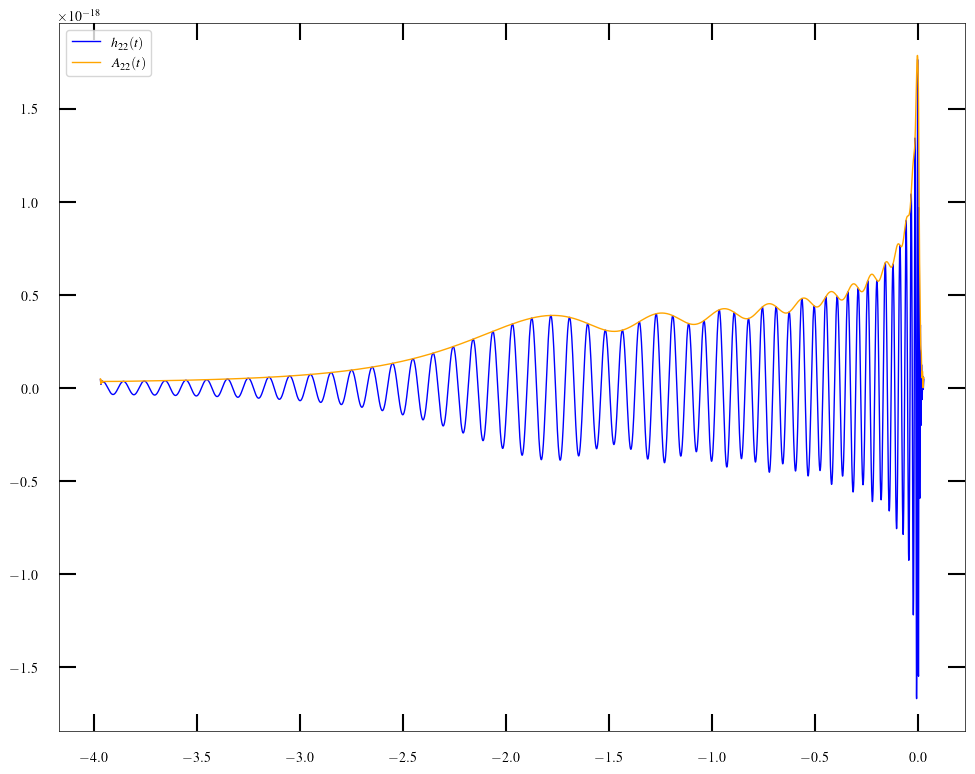

In [30]:
t=4

signal = (hp_lensed[1].to_timeseries().cyclic_time_shift(t-0.03) - 1j * hc_lensed[1].to_timeseries().cyclic_time_shift(t-0.03))

plt.figure(figsize=(10, 8))

plt.plot(signal.sample_times, np.real(signal.data), label=r'$h_{22}(t)$', color='blue')
plt.plot(signal.sample_times, np.abs(signal), label=r'$A_{22}(t)$', color='orange')

plt.legend()
# plt.xlim(-1.0, 0.0)

ax = plt.gca()
set_tick_sizes(ax, major=12, minor=7)
plt.tight_layout()
plt.show()

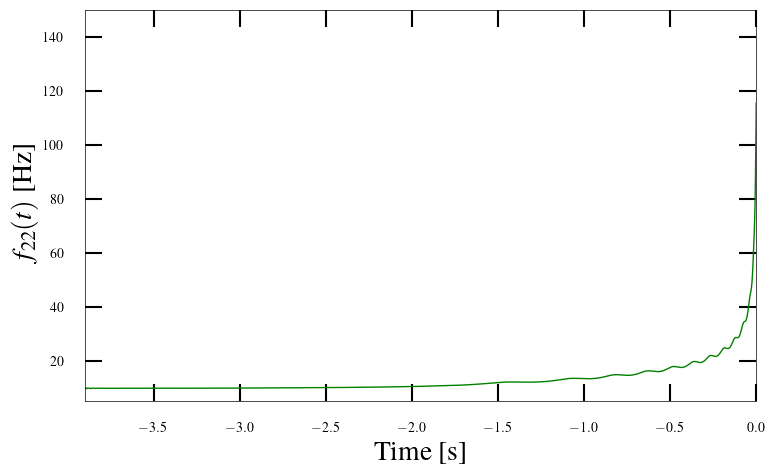

In [31]:
signal = (
    hp_lensed[1].to_timeseries().cyclic_time_shift(t-0.03)
    - 1j * hc_lensed[1].to_timeseries().cyclic_time_shift(t-0.03)
)

time = signal.sample_times
h = signal.data

# phase
phi = np.unwrap(np.angle(h))

# time step
dt = time[1] - time[0]

# instantaneous frequency
freq = -np.gradient(phi, dt) / (2 * np.pi)

plt.figure(figsize=(8, 5))
plt.plot(time, freq, color='green')

plt.xlabel("Time [s]")
plt.ylabel(r"$f_{22}(t)$ [Hz]")

ax = plt.gca()
set_tick_sizes(ax, major=12, minor=7)
plt.ylim(5, 150)
# plt.xlim(-0.7, 0.0)
plt.xlim(-3.9, 0.0)

plt.tight_layout()
plt.show()